# 07 · Random Forest

**Random Forest** construye muchos árboles de decisión, cada uno con una muestra aleatoria de reseñas y de palabras, y combina
sus votos. Es robusto, pero con miles de características dispersas (TF-IDF) suele ser más lento que los modelos lineales.

- `n_estimators`: número de árboles.
- `max_depth`: profundidad máxima (`None` = sin límite).
- `min_samples_leaf`: mínimo de reseñas por hoja (valores mayores = árboles más simples, menos sobreajuste).
- `class_weight="balanced"` para la clase minoritaria (Envío).
- `n_jobs=1` dentro del modelo para que el **tiempo de entrenamiento** sea comparable con los otros modelos (un solo núcleo);
  la búsqueda sí paraleliza los pliegues.

**Estructura del notebook** (igual para los 4 modelos, para que la comparación sea justa):
1. Cargar la partición fija (columna `particion`) y el texto preprocesado.
2. Definir el `Pipeline` TF-IDF + clasificador y la malla de hiperparámetros.
3. `GridSearchCV` con validación cruzada estratificada de 5 pliegues **solo sobre entrenamiento** (métrica: F1 macro).
4. Reentrenar con los mejores hiperparámetros y medir tiempos de entrenamiento y predicción.
5. Evaluar en prueba: accuracy, precisión, recall, F1 (macro, ponderado y por clase), matriz de confusión.
6. Guardar predicciones, métricas y el modelo (`joblib`).
7. Análisis de errores y palabras más influyentes.
8. Función para clasificar una reseña nueva.

In [1]:
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

import utils
from utils import CLASES, SEMILLA, RESULTADOS, MODELOS

NOMBRE = "Random Forest"
CLAVE = utils.MODELOS_PROYECTO[NOMBRE]          # nombre de carpeta / archivo
SALIDA = RESULTADOS / CLAVE                       # resultados/{clave}/
SALIDA.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)

# Partición fija generada en el notebook 02 (la misma para los 4 modelos)
df, entrenamiento, prueba = utils.cargar_particiones()
X_train, y_train = entrenamiento["texto_procesado"], entrenamiento["etiqueta_reglas"]
X_test, y_test = prueba["texto_procesado"], prueba["etiqueta_reglas"]

print(f"Entrenamiento: {len(X_train)} reseñas | Prueba: {len(X_test)} reseñas")
pd.DataFrame({"entrenamiento": y_train.value_counts(), "prueba": y_test.value_counts()}).reindex(CLASES)

Entrenamiento: 11860 reseñas | Prueba: 2966 reseñas


,entrenamiento,prueba
etiqueta_reglas,,
Envío,274,68
Producto,4613,1154
Sentimiento,6973,1744


## 1. Pipeline y malla de hiperparámetros

TF-IDF + `RandomForestClassifier(class_weight="balanced")`. Se buscan `n_estimators`, `max_depth` y `min_samples_leaf`.

In [2]:
pipeline = Pipeline([
    ("tfidf", utils.crear_vectorizador()),
    ("clf", RandomForestClassifier(class_weight="balanced", random_state=SEMILLA, n_jobs=1)),
])
malla = {
    "clf__n_estimators": [200, 400],
    "clf__max_depth": [None, 60],
    "clf__min_samples_leaf": [1, 2, 5],
}
print("Combinaciones a evaluar:", np.prod([len(v) for v in malla.values()]), "x 5 pliegues")

Combinaciones a evaluar: 12 x 5 pliegues


## 2. Búsqueda de hiperparámetros con validación cruzada (solo entrenamiento)

`GridSearchCV` prueba todas las combinaciones con **validación cruzada estratificada de 5 pliegues** (`random_state=42`) usando
**F1 macro** como criterio (también registra accuracy). Como el TF-IDF está dentro del `Pipeline`, en cada pliegue el vocabulario
se aprende solo con los datos de entrenamiento de ese pliegue: **no hay fuga de información**. El conjunto de prueba no se toca aquí.

In [3]:
busqueda, tiempo_busqueda = utils.buscar_hiperparametros(pipeline, malla, X_train, y_train)
print(f"Tiempo total de la búsqueda: {tiempo_busqueda:.1f} s")
print("Mejores hiperparámetros:", busqueda.best_params_)

cv = utils.resumen_cv(busqueda)
print(f"F1 macro en CV (5 pliegues): {cv['cv_f1_macro_media']:.4f} ± {cv['cv_f1_macro_std']:.4f}")
print(f"Accuracy en CV (5 pliegues): {cv['cv_accuracy_media']:.4f} ± {cv['cv_accuracy_std']:.4f}")

mejores, todas = utils.tabla_busqueda(busqueda)
todas.to_csv(SALIDA / "busqueda_hiperparametros.csv", index=False, encoding="utf-8-sig")
mejores.round(4)

Tiempo total de la búsqueda: 227.8 s
Mejores hiperparámetros: {'clf__max_depth': None, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 200}
F1 macro en CV (5 pliegues): 0.6973 ± 0.0234
Accuracy en CV (5 pliegues): 0.7846 ± 0.0067


,params,mean_test_f1_macro,std_test_f1_macro,mean_test_accuracy,std_test_accuracy,mean_fit_time,rank_test_f1_macro
0,"{'clf__max_depth': None, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 200}",0.6973,0.0234,0.7846,0.0067,30.6471,1
1,"{'clf__max_depth': None, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 400}",0.6940,0.0145,0.7843,0.0065,57.6080,2
2,"{'clf__max_depth': 60, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 400}",0.6766,0.0125,0.7593,0.0073,32.9455,3
3,"{'clf__max_depth': 60, 'clf__min_samples_leaf': 2, 'clf__n_estimators': 200}",0.6721,0.0106,0.7579,0.0088,22.4069,4
4,"{'clf__max_depth': None, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 400}",0.6504,0.0055,0.7533,0.0063,26.6977,5
5,"{'clf__max_depth': None, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}",0.6473,0.0053,0.7519,0.0050,16.0726,6
6,"{'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 400}",0.6385,0.0377,0.7933,0.0046,164.6750,7
7,"{'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200}",0.6362,0.0420,0.7889,0.0048,83.5480,8
8,"{'clf__max_depth': 60, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 400}",0.6361,0.0090,0.7410,0.0067,16.9635,9
9,"{'clf__max_depth': 60, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200}",0.6344,0.0080,0.7401,0.0088,13.5534,10


## 3. Reentrenar con los mejores hiperparámetros y medir tiempos

Se clona el mejor pipeline y se entrena de nuevo con **todo** el conjunto de entrenamiento, midiendo con `time.perf_counter()`:
- **Tiempo de entrenamiento:** ajuste del TF-IDF + clasificador.
- **Tiempo de predicción:** clasificar todas las reseñas de prueba.

Para que la comparación entre modelos sea justa, antes de medir se cierran los procesos auxiliares que dejó `GridSearchCV`
y la medición se repite **3 veces**, reportando la **mediana** (las predicciones son idénticas en cada repetición).

In [4]:
modelo = clone(busqueda.best_estimator_)
modelo, y_pred, t_entrenamiento, t_prediccion = utils.medir_entrenamiento_y_prediccion(modelo, X_train, y_train, X_test)
print(f"Tiempo de entrenamiento (mediana de 3): {t_entrenamiento:.3f} s")
print(f"Tiempo de predicción ({len(X_test)} reseñas): {t_prediccion:.3f} s "
      f"({1000 * t_prediccion / len(X_test):.3f} ms por reseña)")

Tiempo de entrenamiento (mediana de 3): 15.786 s
Tiempo de predicción (2966 reseñas): 0.797 s (0.269 ms por reseña)


## 4. Evaluación en el conjunto de prueba

In [5]:
metricas = utils.calcular_metricas(y_test, y_pred)
metricas.update(cv)
metricas.update({
    "tiempo_busqueda_s": tiempo_busqueda,
    "tiempo_entrenamiento_s": t_entrenamiento,
    "tiempo_prediccion_s": t_prediccion,
    "mejores_hiperparametros": {k: str(v) for k, v in busqueda.best_params_.items()},
})
metricas = utils.guardar_metricas(NOMBRE, metricas, SALIDA)
reporte = utils.guardar_reporte(NOMBRE, y_test, y_pred, metricas, SALIDA)
print(reporte)
print(f"Accuracy: {metricas['accuracy']:.4f} | F1 macro: {metricas['f1_macro']:.4f} | "
      f"F1 ponderado: {metricas['f1_ponderado']:.4f} | Errores: {metricas['n_errores']} de {metricas['n_prueba']}")

              precision    recall  f1-score   support

       Envío     0.4648    0.4853    0.4748        68
    Producto     0.7171    0.7643    0.7399      1154
 Sentimiento     0.8468    0.8085    0.8272      1744

    accuracy                         0.7839      2966
   macro avg     0.6762    0.6860    0.6807      2966
weighted avg     0.7876    0.7839    0.7852      2966

Accuracy: 0.7839 | F1 macro: 0.6807 | F1 ponderado: 0.7852 | Errores: 641 de 2966


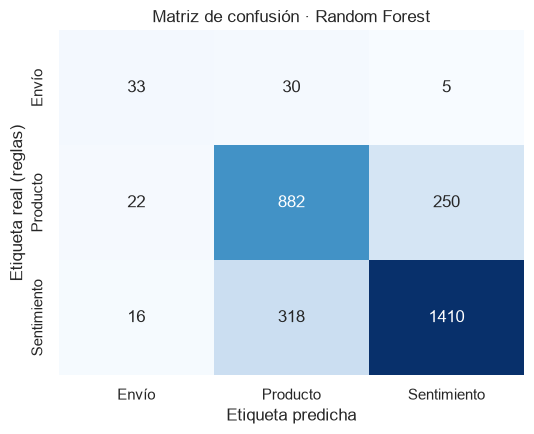

,pred_Envío,pred_Producto,pred_Sentimiento
real_Envío,33,30,5
real_Producto,22,882,250
real_Sentimiento,16,318,1410


In [6]:
matriz = utils.graficar_matriz_confusion(y_test, y_pred, f"Matriz de confusión · {NOMBRE}", SALIDA)
plt.show()
matriz

## 5. Guardar predicciones y modelo

- `predicciones_prueba.csv`: texto, estrellas, etiqueta real (reglas), etiqueta predicha, si acertó y la confianza por clase.
- `modelos/<modelo>.joblib`: el pipeline completo (TF-IDF + clasificador), listo para clasificar texto preprocesado.
- `mejores_hiperparametros.json`.

In [7]:
predicciones = utils.guardar_predicciones(prueba, y_pred, modelo, SALIDA)
joblib.dump(modelo, MODELOS / f"{CLAVE}.joblib")
with open(SALIDA / "mejores_hiperparametros.json", "w", encoding="utf-8") as f:
    json.dump(metricas["mejores_hiperparametros"], f, ensure_ascii=False, indent=2)
print("Guardados:", (SALIDA / "predicciones_prueba.csv").relative_to(utils.BASE), "|",
      (MODELOS / f"{CLAVE}.joblib").relative_to(utils.BASE))
predicciones.head()

Guardados: resultados\random_forest\predicciones_prueba.csv | modelos\random_forest.joblib


,id,text,rating,polarity,etiqueta_real,etiqueta_predicha,correcta,confianza_Envío,confianza_Producto,confianza_Sentimiento
0,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B004OF968O_1493389988000,"Not for me..... I was not expecting much, but for me, these bags are a joke. I can't believe so many are still available, but impossible to find out who actually makes them. I wanted to make a s...",1.0,negative,Sentimiento,Producto,False,0.0900,0.5820,0.3280
1,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B00P9UC004_1521055721867,"Very small size. These are so small everything falls off. Too small for baseball caps, they just fall off. The pictures do not show the scale. Good if you want to hang a few rubber bands on hoo...",1.0,negative,Producto,Sentimiento,False,0.0823,0.4214,0.4963
2,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B081B65WT8_1591466996903,Did not work for me. I always have a problem when cooking pasta sauce on my glass stove top. I purchased a counter top induction burner and a new SS 16 qt stock pot along with this item. $$$$$ s...,2.0,negative,Producto,Producto,True,0.0638,0.7038,0.2323
3,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B08G7Y67GH_1617298313281,UPDATE. Originally said this was a good deal....does the job.....bit after only three times with an egg one of the wires broke and hangs loose so now the slicer is useless. NOT a good deal and no...,1.0,negative,Producto,Producto,True,0.1667,0.6318,0.2015
4,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B08NVKYLGV_1521054740535,"Should have sent it back...!!. I like the product just fine, but almost returned it because the large product label was so hard to remove, I ended up scratching the plastic. Now every time the lig...",2.0,negative,Producto,Producto,True,0.2875,0.4565,0.2560


## 6. Análisis de errores

### 6.1 ¿Qué confusiones son más frecuentes? Ejemplos reales

In [8]:
conteo_errores, ejemplos = utils.ejemplos_errores(predicciones, SALIDA, n_por_tipo=3)
display(conteo_errores)
for (real, pred), grupo in ejemplos.groupby(["etiqueta_real", "etiqueta_predicha"], sort=False):
    print(f"\n--- Real: {real}  ->  Predicha: {pred} ---")
    for _, fila in grupo.iterrows():
        print(f"  [{int(fila['rating'])}★] {fila['text']}")

,etiqueta_real,etiqueta_predicha,n_errores
0,Sentimiento,Producto,318
1,Producto,Sentimiento,250
2,Envío,Producto,30
3,Producto,Envío,22
4,Sentimiento,Envío,16
5,Envío,Sentimiento,5



--- Real: Sentimiento  ->  Predicha: Producto ---
  [3★] Not worth the effort!. I think this is a case where the old fashioned way is better.  Pull the pot out,  fille it with water and time your eggs on the stove.  There are too many devices for us these days.  We do not need more that are not necessary.  I would not try cooking a scrambled egg.  I have 
  [2★] Fragrance is overpowering and headache producing; this is liquid free. This is totally not what I expected. First of all, I thought it was a liquid diffuser but I did not read the label correctly.  Secondly, the scent is so overpowering, that I have a headache as a result and the reeds are in a diff
  [3★] Okay bag.. This will work but isn't quite what I expected.

--- Real: Producto  ->  Predicha: Sentimiento ---
  [3★] Not what I expected. Have to be plugged in at all times The cord is too short for some rooms
  [1★] Horrible dirty stains. Dirty stains on inside and outside of the spread. I am returning it!
  [1★] Unstable. 

### 6.2 ¿Se clasifican peor las reseñas de 3 estrellas (neutral)?

In [9]:
por_polaridad = utils.desempeno_por_polaridad(predicciones, SALIDA)
por_polaridad.round(4)

,polaridad,n,accuracy,f1_macro
0,negative,955,0.7592,0.6935
1,neutral,1022,0.7123,0.5942
2,positive,989,0.8817,0.6359


### 6.3 Palabras más influyentes

Random Forest da una **importancia global** por término (reducción media de impureza), no por clase. Para saber hacia qué clase
apunta cada término, se muestra también en qué clase tiene mayor TF-IDF promedio.

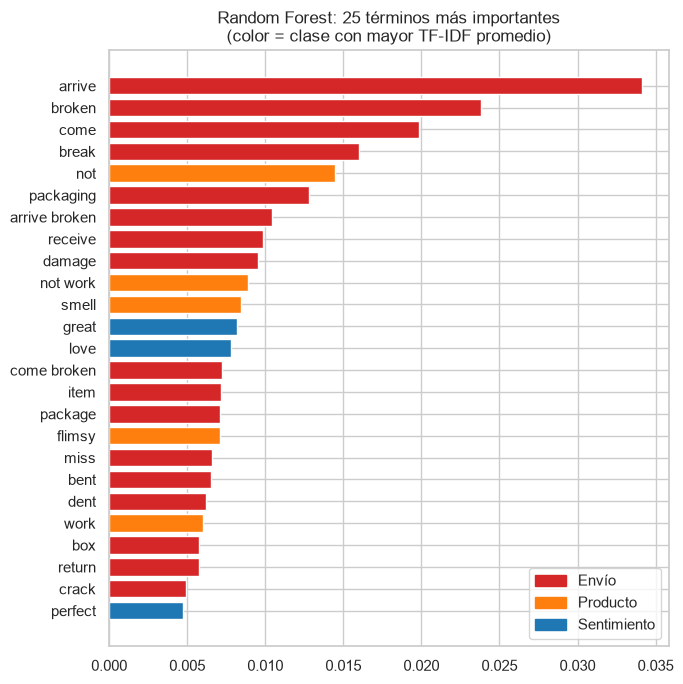

,termino,importancia,clase_con_mayor_tfidf
0,arrive,0.03413,Envío
1,broken,0.02380,Envío
2,come,0.01985,Envío
3,break,0.01599,Envío
4,not,0.01447,Producto
5,packaging,0.01281,Envío
6,arrive broken,0.01043,Envío
7,receive,0.00988,Envío
8,damage,0.00955,Envío
9,not work,0.00889,Producto


In [10]:
tfidf, rf_clf = modelo.named_steps["tfidf"], modelo.named_steps["clf"]
vocabulario = tfidf.get_feature_names_out()
importancias = rf_clf.feature_importances_
orden = np.argsort(importancias)[::-1][:25]

X_tr = tfidf.transform(X_train)
promedios = pd.DataFrame({c: np.asarray(X_tr[(y_train == c).values].mean(axis=0)).ravel()[orden] for c in CLASES})
influyentes = pd.DataFrame({"termino": vocabulario[orden], "importancia": importancias[orden].round(5),
                            "clase_con_mayor_tfidf": promedios.idxmax(axis=1).values})
influyentes.to_csv(SALIDA / "palabras_influyentes.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(7, 7))
colores = {"Envío": "tab:red", "Producto": "tab:orange", "Sentimiento": "tab:blue"}
ax.barh(influyentes["termino"][::-1], influyentes["importancia"][::-1],
        color=[colores[c] for c in influyentes["clase_con_mayor_tfidf"][::-1]])
ax.set_title("Random Forest: 25 términos más importantes\n(color = clase con mayor TF-IDF promedio)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=v, label=k) for k, v in colores.items()], loc="lower right")
fig.tight_layout(); fig.savefig(SALIDA / "palabras_influyentes.png", dpi=120); plt.show()
influyentes

## 7. Clasificar una reseña nueva

La reseña se preprocesa exactamente igual que en el entrenamiento (`utils.preprocesar_texto`) y luego pasa por el pipeline
(TF-IDF + clasificador).

In [11]:
def clasificar_texto(texto):
    procesado = utils.preprocesar_texto(texto)
    confianzas, tipo = utils.puntajes_confianza(modelo, [procesado])
    etiqueta = modelo.predict([procesado])[0]
    detalle = {c: round(float(p), 3) for c, p in zip(modelo.classes_, confianzas[0])}
    return etiqueta, detalle

for resena in ["The box arrived crushed and two glasses were broken.",
               "The blender stopped working after a week, the motor smells like burning.",
               "Absolutely love these towels, they are soft and beautiful!"]:
    etiqueta, detalle = clasificar_texto(resena)
    print(f"{etiqueta:12s} {detalle}  <-  {resena}")

Envío        {'Envío': 0.619, 'Producto': 0.24, 'Sentimiento': 0.142}  <-  The box arrived crushed and two glasses were broken.
Producto     {'Envío': 0.027, 'Producto': 0.809, 'Sentimiento': 0.165}  <-  The blender stopped working after a week, the motor smells like burning.
Sentimiento  {'Envío': 0.022, 'Producto': 0.095, 'Sentimiento': 0.883}  <-  Absolutely love these towels, they are soft and beautiful!
